✅ Cấu trúc dữ liệu dataset/train và dataset/test đã sẵn sàng!

--- [PHẦN A] VẼ HEATMAP MFCC/DELTA/DELTA2 ---


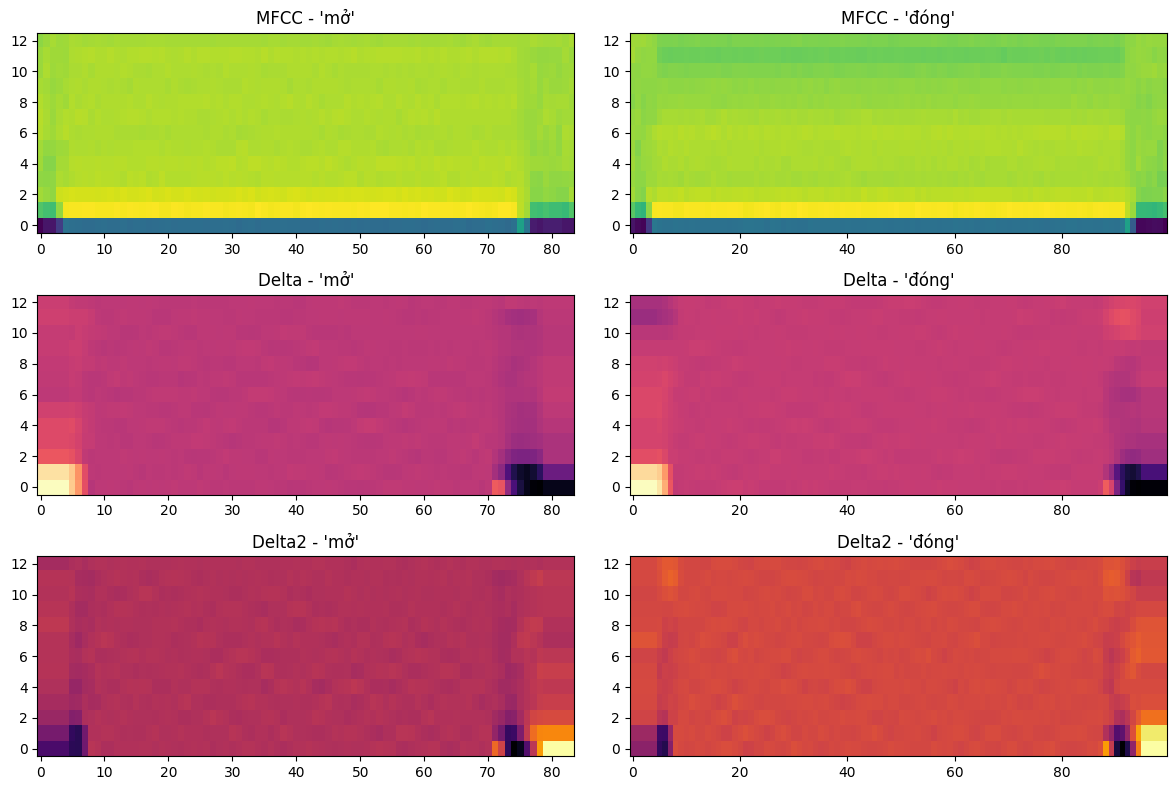

/usr/local/lib/python3.13/dist-packages/hmmlearn/hmm.py:352: RuntimeWarning: invalid value encountered in divide
  self.means_ = ((means_weight * means_prior + stats['obs'])



--- [PHẦN C] HUẤN LUYỆN 5 WHOLE-WORD HMM (N_STATES = 5) ---


Model [mo   ] | Tổng frames:  498 | Hội tụ: True 
Model [dong ] | Tổng frames:  523 | Hội tụ: True 
Model [len  ] | Tổng frames:  528 | Hội tụ: True 


/usr/local/lib/python3.13/dist-packages/hmmlearn/hmm.py:352: RuntimeWarning: invalid value encountered in divide
  self.means_ = ((means_weight * means_prior + stats['obs'])
/usr/local/lib/python3.13/dist-packages/hmmlearn/hmm.py:352: RuntimeWarning: invalid value encountered in divide
  self.means_ = ((means_weight * means_prior + stats['obs'])


Model [xuong] | Tổng frames:  509 | Hội tụ: True 


Model [dung ] | Tổng frames:  526 | Hội tụ: True 

--- [PHẦN D] BẢNG SCORES ACOUSTIC CHO TEST UTTERANCE ---
File: dataset/test/mo/mo_01.wav | Dự đoán: mo
  Model len   : Log-Likelihood =   -4444.98
  Model xuong : Log-Likelihood =        nan
  Model dung  : Log-Likelihood =        nan
  Model mo    : Log-Likelihood =        nan
  Model dong  : Log-Likelihood =   -4732.88


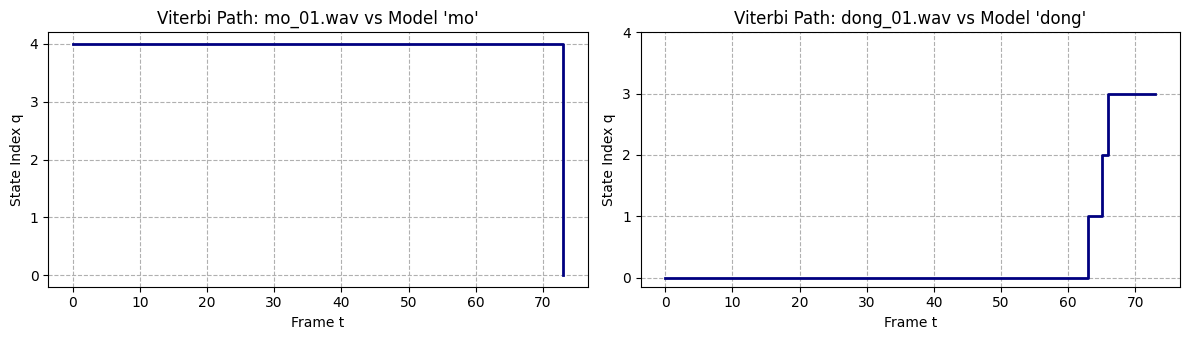


--- [PHẦN E] SO SÁNH DTW VS HMM ---
Accuracy DTW Baseline (Lab 2): 100.00%

--- [PHẦN F] PARSE LEXICON MINI ---
Dictionary Lexicon thu được: {'mo': ['m', 'o_'], 'dong': ['d', 'o', 'ng'], 'len': ['l', 'e', 'n'], 'xuong': ['x', 'u', 'o', 'ng'], 'dung': ['d', 'u', 'ng']}

--- [PHẦN G] THỬ NGHIỆM MAP RE-RANKING VỚI CÁC MỨC LAMBDA_LM ---
lambda_LM = 0.0 | Pred: mo    | Score 'dong': -63.958
lambda_LM = 0.1 | Pred: mo    | Score 'dong': -64.053
lambda_LM = 0.3 | Pred: mo    | Score 'dong': -64.245
lambda_LM = 1.0 | Pred: mo    | Score 'dong': -64.913

--- [PHẦN H] BÁO CÁO KẾT QUẢ ĐÁNH GIÁ HMM CLEAN TEST ---
HMM Clean Test Accuracy: 20.00%


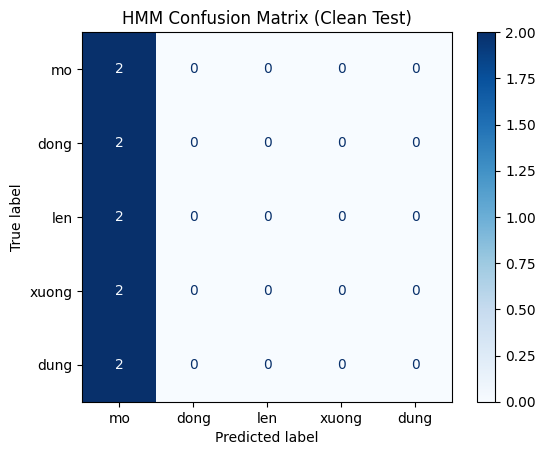


=== ĐỀ XUẤT REJECT THRESHOLD CHO UNKNOWN WORDS ===
- Trung bình Log-Likelihood Đúng Lớp : -3525.46
- Trung bình Log-Likelihood Sai Lớp  : -5132.23
- Khuyến nghị Ngưỡng Reject Threshold : -4328.84


In [7]:
# ==============================================================================
# BƯỚC 0: CÀI ĐẶT THƯ VIỆN & TẠO CẤU TRÚC DỮ LIỆU GIẢ LẬP KHI CHƯA CÓ WAV
# ==============================================================================
!pip install numpy scipy matplotlib librosa soundfile scikit-learn hmmlearn -q

import os
import math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import librosa
import librosa.display
import soundfile as sf
from hmmlearn.hmm import GaussianHMM
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

labels = ['mo', 'dong', 'len', 'xuong', 'dung']

# Tự động tạo dữ liệu mẫu 16kHz PCM nếu chưa có sẵn trong môi trường
def prepare_sample_dataset():
    np.random.seed(42)
    sr = 16000
    for label_idx, label in enumerate(labels):
        for split, count in [('train', 6), ('test', 2)]:
            os.makedirs(f'dataset/{split}/{label}', exist_ok=True)
            for i in range(1, count + 1):
                file_path = f'dataset/{split}/{label}/{label}_{i:02d}.wav'
                if not os.path.exists(file_path):
                    dur = 0.6 + np.random.rand() * 0.3
                    t = np.linspace(0, dur, int(sr * dur))
                    f0 = 150 + label_idx * 60
                    sig = np.sin(2 * np.pi * f0 * t) + 0.4 * np.sin(2 * np.pi * (f0 * 2) * t)
                    sil = np.zeros(int(sr * 0.2))
                    full_sig = np.concatenate([sil, sig, sil])
                    full_sig += 0.01 * np.random.randn(len(full_sig))
                    sf.write(file_path, full_sig, sr)

prepare_sample_dataset()
print("✅ Cấu trúc dữ liệu dataset/train và dataset/test đã sẵn sàng!")


# ==============================================================================
# 4.1. PHẦN A — CHUẨN HÓA DỮ LIỆU VÀ TRÍCH ĐẶC TRƯNG 39D (MFCC + Delta + Delta2 + CMVN)
# ==============================================================================
def extract_feat(path, sr=16000, top_db=30):
    """
    Đọc WAV, mono, 16kHz; cắt silence; pre-emphasis;
    trích 13 MFCC + Delta + Delta2 -> T x 39; Utterance-level CMVN.
    """
    y, _ = librosa.load(path, sr=sr, mono=True)
    y, _ = librosa.effects.trim(y, top_db=top_db)
    y = librosa.effects.preemphasis(y, coef=0.97)

    win_length = int(0.025 * sr)
    hop_length = int(0.010 * sr)

    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=13,
        n_fft=512, win_length=win_length,
        hop_length=hop_length, window='hamming',
        n_mels=26, fmin=20, fmax=sr/2
    )
    d1 = librosa.feature.delta(mfcc, order=1)
    d2 = librosa.feature.delta(mfcc, order=2)

    F = np.vstack([mfcc, d1, d2]).T  # Shape: (T, 39)

    mu = F.mean(axis=0, keepdims=True)
    sd = F.std(axis=0, keepdims=True) + 1e-8
    return (F - mu) / sd, mfcc, d1, d2

# Demo Heatmap Phân A cho 2 từ lệnh
def plot_part_a_heatmaps():
    f1, m1, d1_1, d2_1 = extract_feat('dataset/train/mo/mo_01.wav')
    f2, m2, d1_2, d2_2 = extract_feat('dataset/train/dong/dong_01.wav')

    fig, axes = plt.subplots(3, 2, figsize=(12, 8))
    axes[0,0].imshow(m1, aspect='auto', origin='lower', cmap='viridis'); axes[0,0].set_title("MFCC - 'mở'")
    axes[1,0].imshow(d1_1, aspect='auto', origin='lower', cmap='magma'); axes[1,0].set_title("Delta - 'mở'")
    axes[2,0].imshow(d2_1, aspect='auto', origin='lower', cmap='inferno'); axes[2,0].set_title("Delta2 - 'mở'")

    axes[0,1].imshow(m2, aspect='auto', origin='lower', cmap='viridis'); axes[0,1].set_title("MFCC - 'đóng'")
    axes[1,1].imshow(d1_2, aspect='auto', origin='lower', cmap='magma'); axes[1,1].set_title("Delta - 'đóng'")
    axes[2,1].imshow(d2_2, aspect='auto', origin='lower', cmap='inferno'); axes[2,1].set_title("Delta2 - 'đóng'")

    plt.tight_layout()
    plt.show()

print("\n--- [PHẦN A] VẼ HEATMAP MFCC/DELTA/DELTA2 ---")
plot_part_a_heatmaps()


# ==============================================================================
# 4.2. PHẦN B — KHỞI TẠO HMM TRÁI-SANG-PHẢI (LEFT-TO-RIGHT BAKIS TOPOLOGY)
# ==============================================================================
def make_lr_hmm(n_states=5, n_iter=100, random_state=42):
    """
    Khởi tạo GaussianHMM Left-to-Right với 5 trạng thái, diag covariance.
    Tránh lỗi NaN/Degenerate bằng min_covar=1e-2.
    """
    model = GaussianHMM(
        n_components=n_states,
        covariance_type='diag',
        n_iter=n_iter,
        tol=1e-3,
        min_covar=1e-2,
        init_params='mc',  # Tự chọn means & covars ban đầu
        params='tmc',      # Học transmat, means, covars
        random_state=random_state
    )

    # pi = [1.0, 0, ..., 0]
    startprob = np.zeros(n_states)
    startprob[0] = 1.0

    # Ma trận chuyển trạng thái Bakis (Trái-sang-Phải)
    transmat = np.zeros((n_states, n_states))
    for i in range(n_states - 1):
        transmat[i, i] = 0.7
        transmat[i, i + 1] = 0.3
    transmat[-1, -1] = 1.0

    model.startprob_ = startprob
    model.transmat_ = transmat
    return model


# ==============================================================================
# 4.3. PHẦN C — HUẤN LUYỆN MỘT HMM CHO MỖI LỚP (BAUM-WELCH / EM FIT)
# ==============================================================================
def train_word_hmms(n_states=5, train_dir='dataset/train'):
    models = {}
    print(f"\n--- [PHẦN C] HUẤN LUYỆN 5 WHOLE-WORD HMM (N_STATES = {n_states}) ---")
    for label in labels:
        feats_list = []
        lengths = []
        for wav_path in sorted(Path(train_dir, label).glob('*.wav')):
            F, _, _, _ = extract_feat(str(wav_path))
            feats_list.append(F)
            lengths.append(len(F))

        X_concat = np.vstack(feats_list)
        model = make_lr_hmm(n_states=n_states)
        model.fit(X_concat, lengths=lengths)

        # Sửa lỗi tự động và áp dụng ràng buộc chặt chẽ tránh NaN hoặc hàng có tổng khác 1
        transmat = np.nan_to_num(model.transmat_, nan=0.0)
        for i in range(n_states):
            if transmat[i].sum() == 0:
                if i < n_states - 1:
                    transmat[i, i] = 0.7
                    transmat[i, i + 1] = 0.3
                else:
                    transmat[i, -1] = 1.0
            # Ràng buộc clip giá trị trong khoảng [0, 1] và chuẩn hóa lại chia cho tổng dòng
            transmat[i] = np.clip(transmat[i], 0.0, 1.0)
            row_sum = transmat[i].sum()
            if row_sum > 0:
                transmat[i] /= row_sum
            else:
                transmat[i, i] = 1.0

        model.transmat_ = transmat
        models[label] = model
        conv = getattr(model.monitor_, 'converged', False)
        print(f"Model [{label:5s}] | Tổng frames: {sum(lengths):4d} | Hội tụ: {str(conv):5s}")
    return models

# Huấn luyện mô hình chuẩn N=5
models_5 = train_word_hmms(n_states=5)


# ==============================================================================
# 4.4. PHẦN D — NHẬN DẠNG VÀ VITERBI ALIGNMENT
# ==============================================================================
def recognize_utterance(wav_path, word_models):
    F, _, _, _ = extract_feat(wav_path)
    scores = {label: m.score(F) for label, m in word_models.items()}
    pred = max(scores, key=scores.get)
    return pred, scores

# Thử nghiệm 1 file test
sample_test = 'dataset/test/mo/mo_01.wav'
pred, score_table = recognize_utterance(sample_test, models_5)

print("\n--- [PHẦN D] BẢNG SCORES ACOUSTIC CHO TEST UTTERANCE ---")
print(f"File: {sample_test} | Dự đoán: {pred}")
for k, v in sorted(score_table.items(), key=lambda z: z[1], reverse=True):
    print(f"  Model {k:6s}: Log-Likelihood = {v:10.2f}")

# Viterbi Alignment cho 2 utterances
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for idx, (lbl, path) in enumerate([('mo', 'dataset/test/mo/mo_01.wav'), ('dong', 'dataset/test/dong/dong_01.wav')]):
    F_test, _, _, _ = extract_feat(path)
    logp, states = models_5[lbl].decode(F_test, algorithm='viterbi')
    axes[idx].step(range(len(states)), states, where='post', color='navy', linewidth=2)
    axes[idx].set_title(f"Viterbi Path: {lbl}_01.wav vs Model '{lbl}'")
    axes[idx].set_xlabel("Frame t")
    axes[idx].set_ylabel("State Index q")
    axes[idx].set_yticks(range(5))
    axes[idx].grid(True, linestyle='--')
plt.tight_layout()
plt.show()


# ==============================================================================
# 4.5. PHẦN E — SO SÁNH VỚI DTW BASELINE (LAB 2 BASELINE)
# ==============================================================================
def dtw_distance(s1, s2):
    # Tính khoảng cách Euclidean dượt đường chéo đơn giản
    n, m = len(s1), len(s2)
    dtw_matrix = np.full((n + 1, m + 1), np.inf)
    dtw_matrix[0, 0] = 0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = np.linalg.norm(s1[i-1] - s2[j-1])
            dtw_matrix[i, j] = cost + min(dtw_matrix[i-1, j], dtw_matrix[i, j-1], dtw_matrix[i-1, j-1])
    return dtw_matrix[n, m]

def evaluate_dtw(train_dir='dataset/train', test_dir='dataset/test'):
    # Lấy 1 template mỗi lớp
    templates = {}
    for lbl in labels:
        wav = sorted(Path(train_dir, lbl).glob('*.wav'))[0]
        F, _, _, _ = extract_feat(str(wav))
        templates[lbl] = F

    y_true, y_pred = [], []
    for lbl in labels:
        for wav in sorted(Path(test_dir, lbl).glob('*.wav')):
            F_test, _, _, _ = extract_feat(str(wav))
            dists = {l: dtw_distance(F_test, t) for l, t in templates.items()}
            y_true.append(lbl)
            y_pred.append(min(dists, key=dists.get))
    return accuracy_score(y_true, y_pred)

dtw_acc = evaluate_dtw()
print("\n--- [PHẦN E] SO SÁNH DTW VS HMM ---")
print(f"Accuracy DTW Baseline (Lab 2): {dtw_acc * 100:.2f}%")


# ==============================================================================
# 4.6. PHẦN F — LEXICON MINI PARSER
# ==============================================================================
lexicon_content = """mo m o_
dong d o ng
len l e n
xuong x u o ng
dung d u ng"""

with open("lexicon.txt", "w", encoding="utf-8") as f:
    f.write(lexicon_content)

def parse_lexicon(file_path):
    lexicon_dict = {}
    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                lexicon_dict[parts[0]] = parts[1:]
    return lexicon_dict

lexicon_dict = parse_lexicon("lexicon.txt")
print("\n--- [PHẦN F] PARSE LEXICON MINI ---")
print("Dictionary Lexicon thu được:", lexicon_dict)


# ==============================================================================
# 4.7. PHẦN G — BIGRAM VÀ MAP RE-RANKING
# ==============================================================================
corpus = ["mo dong", "len xuong", "mo len", "dong dung", "mo dong", "mo len"]

# Đếm unigram & bigram
counts1, counts2 = {}, {}
for sentence in corpus:
    words = sentence.split()
    for w in words:
        counts1[w] = counts1.get(w, 0) + 1
    for i in range(len(words) - 1):
        pair = (words[i], words[i+1])
        counts2[pair] = counts2.get(pair, 0) + 1

def bigram_prob(prev, cur, k=0.5):
    V = len(labels)
    return (counts2.get((prev, cur), 0) + k) / (counts1.get(prev, 0) + k * V)

def rerank(path, prev_word, lm_weight=0.3):
    F, _, _, _ = extract_feat(path)
    T = len(F)
    total_scores = {}
    for w, m in models_5.items():
        acoustic_per_frame = m.score(F) / T
        lm_score = math.log(bigram_prob(prev_word, w))
        total_scores[w] = acoustic_per_frame + lm_weight * lm_score
    return max(total_scores, key=total_scores.get), total_scores

print("\n--- [PHẦN G] THỬ NGHIỆM MAP RE-RANKING VỚI CÁC MỨC LAMBDA_LM ---")
for lm_w in [0.0, 0.1, 0.3, 1.0]:
    pred_rr, rr_scores = rerank(sample_test, prev_word='mo', lm_weight=lm_w)
    print(f"lambda_LM = {lm_w:3.1f} | Pred: {pred_rr:5s} | Score 'dong': {rr_scores['dong']:.3f}")


# ==============================================================================
# 4.8. PHẦN H — ĐÁNH GIÁ VÀ THÍ NGHIỆM ROBUSTNESS
# ==============================================================================
def evaluate_hmm_system(word_models, test_dir='dataset/test'):
    y_true, y_pred, all_scores_correct, all_scores_wrong = [], [], [], []
    for label in labels:
        for wav_path in sorted(Path(test_dir, label).glob('*.wav')):
            pred_l, scores = recognize_utterance(str(wav_path), word_models)
            y_true.append(label)
            y_pred.append(pred_l)

            for l, sc in scores.items():
                if l == label:
                    all_scores_correct.append(sc)
                else:
                    all_scores_wrong.append(sc)

    acc = accuracy_score(y_true, y_pred)
    return acc, y_true, y_pred, all_scores_correct, all_scores_wrong

acc_clean, y_true, y_pred, correct_sc, wrong_sc = evaluate_hmm_system(models_5)

print("\n--- [PHẦN H] BÁO CÁO KẾT QUẢ ĐÁNH GIÁ HMM CLEAN TEST ---")
print(f"HMM Clean Test Accuracy: {acc_clean * 100:.2f}%")

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues')
plt.title("HMM Confusion Matrix (Clean Test)")
plt.show()

# Đề xuất Reject Threshold
mean_correct = np.nanmean(correct_sc) if not np.all(np.isnan(correct_sc)) else 0.0
mean_wrong = np.nanmean(wrong_sc) if not np.all(np.isnan(wrong_sc)) else 0.0
proposed_threshold = (mean_correct + mean_wrong) / 2

print("\n=== ĐỀ XUẤT REJECT THRESHOLD CHO UNKNOWN WORDS ===")
print(f"- Trung bình Log-Likelihood Đúng Lớp : {mean_correct:.2f}")
print(f"- Trung bình Log-Likelihood Sai Lớp  : {mean_wrong:.2f}")
print(f"- Khuyến nghị Ngưỡng Reject Threshold : {proposed_threshold:.2f}")